In [1]:
# NOTEBOOK 22 - explainability of the saved WA-TGCN v2 models (no retraining)
# Three views: (1) which past hours the attention layer looks at, (2) exact Shapley values over six
# feature groups, (3) which graph edges the forecast is most sensitive to.
# Everything runs on the 7 saved watgcn_v2_seed*.pt checkpoints and the held-out test windows.
# HOW TO CHECK: this cell only prints a note.
print('XAI on the saved v2 ensemble. Outputs: plots/xai_*.png and results/xai_results.json')

XAI on the saved v2 ensemble. Outputs: plots/xai_*.png and results/xai_results.json


In [2]:
import os, json, time, copy, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')
OUT    = os.path.join(V2_DIR, 'ecotwin_outputs')
SCALER_DIR, PLOT_DIR   = os.path.join(OUT, 'scalers'), os.path.join(OUT, 'plots')
MODEL_DIR, RESULTS_DIR = os.path.join(OUT, 'models'),  os.path.join(OUT, 'results')

DATASET_CSV      = os.path.join(V2_DIR, 'EcoTwin_Final_Dataset.csv')
DYNAMIC_ADJ_PATH = os.path.join(V2_DIR, 'dynamic_adj_matrix.npy')
STATIONS_EXCEL   = os.path.join(V2_DIR, 'Delhi_list_v2.xlsx')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

INPUT_WINDOW, HORIZON = 48, 24
BATCH_SIZE = 16
HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, DROPOUT = 32, 1, 4, 0.2
GCN_HOPS       = 2
LOSS_VOL_ALPHA = 1.0                       # volatility up-weighting (0 = plain Huber)
SEEDS          = [42, 7, 123, 2024, 999, 2025, 77]
THRESHOLD_KM   = 12.0
V2_TAG         = 'watgcn_v2'               # 07's files are never overwritten

print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')
print(f'Seeds : {SEEDS}')

# HOW TO CHECK: should print 'cuda' + your RTX 3050. 'cpu' still works, ~10x slower.

Device: cuda
GPU   : NVIDIA GeForce RTX 3050 6GB Laptop GPU
Seeds : [42, 7, 123, 2024, 999, 2025, 77]


In [3]:
df = pd.read_csv(DATASET_CSV, parse_dates=['Timestamp'])
df['Station'] = df['Station'].str.strip()
df = df.sort_values(['Station', 'Timestamp']).reset_index(drop=True)

df_st = pd.read_excel(STATIONS_EXCEL)
df_st.columns = df_st.columns.str.strip().str.lower()
df_st['station'] = df_st['station'].str.strip()
station_names = df_st['station'].tolist()
lats = df_st['latitude'].values.astype(float)
lons = df_st['longitude'].values.astype(float)
N = len(station_names)

timestamps = np.array(sorted(df['Timestamp'].unique()))
T = len(timestamps)
dyn_adj = np.load(DYNAMIC_ADJ_PATH).astype(np.float32)          # (T,N,N) wind A(t), no self-loops
assert dyn_adj.shape == (T, N, N), (dyn_adj.shape, (T, N, N))

print(f'Stations   : {N}')
print(f'Timestamps : {T:,}  ({timestamps[0]} -> {timestamps[-1]})')
print(f'dyn_adj    : {dyn_adj.shape}  {dyn_adj.nbytes/1e6:.0f} MB')

# geometry for the forecast-climatology graph (same recipe as 03_dynamic_adjacency)
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlmb/2)**2
    return 2*R*np.arctan2(np.sqrt(a), np.sqrt(1-a))

dist_matrix = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            dist_matrix[i, j] = haversine_km(lats[i], lons[i], lats[j], lons[j])
within_threshold = (dist_matrix > 0) & (dist_matrix <= THRESHOLD_KM)
dir_u = np.zeros((N, N)); dir_v = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            de = (lons[j]-lons[i]) * np.cos(np.radians(lats[i]))
            dn = (lats[j]-lats[i])
            nrm = np.hypot(de, dn)
            if nrm > 0:
                dir_u[i, j], dir_v[i, j] = de/nrm, dn/nrm
print(f'Edges within {THRESHOLD_KM} km: {int(within_threshold.sum())}')

# HOW TO CHECK: 'Edges within 12 km' matches 03_dynamic_adjacency. dyn_adj ~105 MB.

Stations   : 37
Timestamps : 19,921  (2024-01-01 00:00:00 -> 2026-04-10 00:00:00)
dyn_adj    : (19921, 37, 37)  109 MB
Edges within 12.0 km: 508


In [4]:
BASE_FEATS = ['pm2.5','pm10','no2','so2','co','o3','rh','at','u_wind','v_wind']
g = df.groupby('Station', sort=False)

df['wspd'] = np.hypot(df['u_wind'], df['v_wind'])

# rolling PM2.5 stats - window ends at 'now' (an observed hour), so no leakage
df['pm_roll6_mean']  = g['pm2.5'].transform(lambda s: s.rolling(6,  min_periods=1).mean())
df['pm_roll6_std']   = g['pm2.5'].transform(lambda s: s.rolling(6,  min_periods=1).std()).fillna(0.0)
df['pm_roll24_mean'] = g['pm2.5'].transform(lambda s: s.rolling(24, min_periods=1).mean())
df['pm_roll24_std']  = g['pm2.5'].transform(lambda s: s.rolling(24, min_periods=1).std()).fillna(0.0)
df['pm_delta3']      = g['pm2.5'].transform(lambda s: s - s.shift(3)).fillna(0.0)

tsg = df.groupby('Timestamp', sort=False)['pm2.5']
df['city_mean_pm']  = tsg.transform('mean')
df['city_max_pm']   = tsg.transform('max')
df['pm_minus_city'] = df['pm2.5'] - df['city_mean_pm']

hh  = df['Timestamp'].dt.hour; dow = df['Timestamp'].dt.dayofweek; mon = df['Timestamp'].dt.month
df['hour_sin'] = np.sin(2*np.pi*hh/24);      df['hour_cos'] = np.cos(2*np.pi*hh/24)
df['dow_sin']  = np.sin(2*np.pi*dow/7);      df['dow_cos']  = np.cos(2*np.pi*dow/7)
df['mon_sin']  = np.sin(2*np.pi*(mon-1)/12); df['mon_cos']  = np.cos(2*np.pi*(mon-1)/12)
df['is_weekend'] = (dow >= 5).astype(float)

FEATURE_COLS = (BASE_FEATS +
    ['wspd','pm_roll6_mean','pm_roll6_std','pm_roll24_mean','pm_roll24_std','pm_delta3',
     'city_mean_pm','city_max_pm','pm_minus_city',
     'hour_sin','hour_cos','dow_sin','dow_cos','mon_sin','mon_cos','is_weekend'])
F = len(FEATURE_COLS)
TIME_COLS = ['hour_sin','hour_cos','dow_sin','dow_cos','mon_sin','mon_cos','is_weekend']
TIME_IDX  = [FEATURE_COLS.index(c) for c in TIME_COLS]

X_full = np.zeros((T, N, F), dtype=np.float32)
for fi, col in enumerate(FEATURE_COLS):
    wide = df.pivot_table(index='Timestamp', columns='Station', values=col).reindex(columns=station_names)
    X_full[:, :, fi] = np.nan_to_num(wide.values.astype(np.float32))
Y_full = X_full[:, :, 0].copy()                                  # PM2.5 target (channel 0)

print(f'F = {F} features')
print(FEATURE_COLS)
print(f'X_full {X_full.shape}  {X_full.nbytes/1e6:.0f} MB   NaNs: {int(np.isnan(X_full).sum())}')

# HOW TO CHECK: F == 26, X_full ~77 MB, NaNs == 0.

C:\Users\jlakk_j7eh5fd\AppData\Local\Temp\ipykernel_5036\382421343.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hh  = df['Timestamp'].dt.hour; dow = df['Timestamp'].dt.dayofweek; mon = df['Timestamp'].dt.month


F = 26 features
['pm2.5', 'pm10', 'no2', 'so2', 'co', 'o3', 'rh', 'at', 'u_wind', 'v_wind', 'wspd', 'pm_roll6_mean', 'pm_roll6_std', 'pm_roll24_mean', 'pm_roll24_std', 'pm_delta3', 'city_mean_pm', 'city_max_pm', 'pm_minus_city', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'mon_sin', 'mon_cos', 'is_weekend']
X_full (19921, 37, 26)  77 MB   NaNs: 0


In [5]:
train_end_idx = int(T * 0.70)                                    # 13944
val_end_idx   = int(T * 0.85)                                    # 16932

def split_starts(lo, hi):
    n = (hi - lo) - (INPUT_WINDOW + HORIZON) + 1                  # windows fully inside [lo,hi)
    return np.arange(lo, lo + n)

train_starts = split_starts(0, train_end_idx)
val_starts   = split_starts(train_end_idx, val_end_idx)
test_starts  = split_starts(val_end_idx, T)
print(f'windows -- train {len(train_starts):,} | val {len(val_starts):,} | test {len(test_starts):,}')

train_ts_mask = np.zeros(T, bool); train_ts_mask[:train_end_idx] = True

feat_scaler = StandardScaler().fit(X_full[train_ts_mask].reshape(-1, F))
Xs_full = feat_scaler.transform(X_full.reshape(-1, F)).reshape(T, N, F).astype(np.float32)

pm_train   = Y_full[train_ts_mask].reshape(-1, 1)
log_scaler = StandardScaler().fit(np.log1p(np.clip(pm_train, 0, None)))
def to_log(a):
    return log_scaler.transform(np.log1p(np.clip(a, 0, None)).reshape(-1, 1)).reshape(a.shape).astype(np.float32)
def from_log(a):
    return np.expm1(log_scaler.inverse_transform(a.reshape(-1, 1)).reshape(a.shape))
Yl_full = to_log(Y_full)                                         # anchor = Yl_full[now] later

_std = Xs_full[train_ts_mask].reshape(-1, F).std(0)
print(f'raw PM2.5 skew {pd.Series(pm_train.ravel()).skew():.2f} -> log skew '
      f'{pd.Series(np.log1p(pm_train.ravel())).skew():.2f}')
print(f'per-feature std after scaling: min {_std.min():.2f}  max {_std.max():.2f}')

del X_full                                                       # free RAM - only Xs_full needed now

# HOW TO CHECK: window counts 13873 / 2917 / 2918 (same as 07). log skew ~0. std ~1.

windows -- train 13,873 | val 2,917 | test 2,918
raw PM2.5 skew 2.56 -> log skew -0.18
per-feature std after scaling: min 1.00  max 1.00


In [6]:
# forecast-horizon adjacency from a TRAIN-only wind climatology
def compute_At_vec(u, v, eps=1e-6):
    align = u[:, None]*dir_u + v[:, None]*dir_v                  # wind at i . direction(i->j)
    A = np.where(within_threshold & (align > 0.0), align/(dist_matrix + eps), 0.0).astype(np.float32)
    rs = A.sum(1, keepdims=True); rs[rs == 0] = 1.0
    return A / rs

trm = df['Timestamp'].isin(pd.DatetimeIndex(timestamps[:train_end_idx]))
cl = (df[trm].assign(mo=df.loc[trm, 'Timestamp'].dt.month - 1,
                     ho=df.loc[trm, 'Timestamp'].dt.hour)
             .groupby(['Station', 'mo', 'ho'])[['u_wind', 'v_wind']].mean())
st_mean = df[trm].groupby('Station')[['u_wind', 'v_wind']].mean()
cl_idx = set(cl.index)

clim_grid = np.zeros((12, 24, N, 2), dtype=np.float32)           # (month, hour, station, uv)
for si, s in enumerate(station_names):
    for mo in range(12):
        for ho in range(24):
            clim_grid[mo, ho, si] = (cl.loc[(s, mo, ho)].values
                                     if (s, mo, ho) in cl_idx else st_mean.loc[s].values)

mo_arr = pd.DatetimeIndex(timestamps).month.values - 1
ho_arr = pd.DatetimeIndex(timestamps).hour.values
t0 = time.time()
dyn_clim = np.zeros((T, N, N), dtype=np.float32)
for t in range(T):
    uv = clim_grid[mo_arr[t], ho_arr[t]]
    dyn_clim[t] = compute_At_vec(uv[:, 0], uv[:, 1])
print(f'dyn_clim {dyn_clim.shape} built in {time.time()-t0:.0f}s  ({dyn_clim.nbytes/1e6:.0f} MB)')
print(f'edges/hr -- hourly A(t) {np.mean((dyn_adj>0).sum((1,2))):.1f} | '
      f'climatology {np.mean((dyn_clim>0).sum((1,2))):.1f}')

import gc; del df, trm, cl; gc.collect()                         # free RAM - df no longer needed

# HOW TO CHECK: climatology edges/hr in the same ballpark as hourly (smoother). <60s.

dyn_clim (19921, 37, 37) built in 0s  (109 MB)
edges/hr -- hourly A(t) 259.6 | climatology 264.1


952

In [7]:
class EcoWindowDS(Dataset):
    """Slices the shared full-length arrays by window-start index - no windowed copies."""
    def __init__(self, starts, weights=None):
        self.s = np.asarray(starts, dtype=np.int64)
        self.w = (weights if weights is not None else np.ones(len(self.s), np.float32)).astype(np.float32)
    def __len__(self):
        return len(self.s)
    def __getitem__(self, k):
        gg = int(self.s[k]); i1 = gg + INPUT_WINDOW; i2 = i1 + HORIZON
        return (torch.from_numpy(Xs_full[gg:i1].copy()),           # (48,N,F)
                torch.from_numpy(dyn_adj[gg:i1].copy()),           # (48,N,N)
                torch.from_numpy(dyn_clim[i1:i2].copy()),          # (24,N,N)
                torch.from_numpy(Xs_full[i1:i2, 0, :][:, TIME_IDX].copy()),  # (24,n_time)
                torch.from_numpy(Yl_full[i1-1].copy()),            # (N,) last obs PM2.5 (log)
                torch.from_numpy(Yl_full[i1:i2].copy()),           # (24,N) target (log)
                torch.tensor(self.w[k], dtype=torch.float32))

test_ld = DataLoader(EcoWindowDS(test_starts), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f'test batches: {len(test_ld)}')
# HOW TO CHECK: test batches 183.

test batches: 183


In [8]:
class WATGCNv2(nn.Module):
    def __init__(self, in_features, hidden_dim, gru_layers, attn_heads,
                 forecast_horizon, n_stations, dropout=0.2, n_time=7, gcn_hops=2):
        super().__init__()
        H = hidden_dim
        self.input_proj = nn.Linear(in_features, H)
        self.gcn_lin  = nn.ModuleList(nn.Linear(H, H) for _ in range(gcn_hops))
        self.gcn_norm = nn.ModuleList(nn.LayerNorm(H) for _ in range(gcn_hops))
        self.act = nn.ReLU()
        self.gru = nn.GRU(H, H, gru_layers, batch_first=True,
                          dropout=dropout if gru_layers > 1 else 0.0)
        self.attn = nn.MultiheadAttention(H, attn_heads, dropout=dropout, batch_first=True)
        self.attn_norm = nn.LayerNorm(H)
        self.dropout = nn.Dropout(dropout)
        self.time_enc = nn.Sequential(nn.Linear(n_time, H), nn.ReLU(), nn.Linear(H, H))
        self.decoder = nn.Sequential(nn.Linear(H*3, H), nn.ReLU(), nn.Dropout(dropout), nn.Linear(H, 1))
        self.anchor_gate = nn.Parameter(torch.linspace(1.0, 0.3, forecast_horizon))
        self.H, self.FH = H, forecast_horizon

    @staticmethod
    def _norm_adj(A, n, device):
        I = torch.eye(n, device=device).unsqueeze(0).unsqueeze(0)
        A = A + I
        return A / A.sum(-1, keepdim=True).clamp(min=1e-6)

    def forward(self, X, At, Afc, TFut, Anchor):
        B, Tin, n, _ = X.shape
        h = self.act(self.input_proj(X))                          # (B,Tin,n,H)
        A = self._norm_adj(At, n, X.device)
        for lin, nrm in zip(self.gcn_lin, self.gcn_norm):
            h = self.act(nrm(lin(torch.matmul(A, h)))) + h        # residual graph hop
        hf = h.permute(0, 2, 1, 3).reshape(B*n, Tin, self.H)
        gg, _ = self.gru(hf)
        gg = self.dropout(gg)
        aa, _ = self.attn(gg, gg, gg)
        ctx = self.attn_norm(aa + gg)[:, -1, :].reshape(B, n, self.H)   # (B,n,H)
        Afc_n = self._norm_adj(Afc, n, X.device)                  # (B,FH,n,n)
        ctx_fc = torch.matmul(Afc_n, ctx.unsqueeze(1).expand(B, self.FH, n, self.H))  # (B,FH,n,H)
        t_emb = self.time_enc(TFut).unsqueeze(2).expand(B, self.FH, n, self.H)
        ctx_rep = ctx.unsqueeze(1).expand(B, self.FH, n, self.H)
        resid = self.decoder(torch.cat([ctx_rep, ctx_fc, t_emb], dim=-1)).squeeze(-1)  # (B,FH,n)
        anchor = Anchor.unsqueeze(1) * self.anchor_gate.view(1, self.FH, 1)
        return resid + anchor

_m = WATGCNv2(F, HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, HORIZON, N, DROPOUT, len(TIME_IDX), GCN_HOPS)
print(f'v2 parameters: {sum(p.numel() for p in _m.parameters()):,}')
del _m

v2 parameters: 18,201


In [9]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); P, A = [], []
    for X, At, Afc, tf, anc, y, w in loader:
        out = model(X.to(DEVICE), At.to(DEVICE), Afc.to(DEVICE), tf.to(DEVICE), anc.to(DEVICE))
        P.append(out.cpu().numpy()); A.append(y.numpy())
    return np.concatenate(P), np.concatenate(A)

def score(pred_log, act_log):
    pr, ar = from_log(pred_log), from_log(act_log)
    return dict(rmse=float(np.sqrt(mean_squared_error(ar.ravel(), pr.ravel()))),
                mae=float(mean_absolute_error(ar.ravel(), pr.ravel())),
                r2=float(r2_score(ar.ravel(), pr.ravel())), preds=pr, actual=ar)

In [10]:
# load the 7 saved v2 models and re-score the test set (this proves the XAI is on the published model)
models = []
for sd in SEEDS:
    m = WATGCNv2(F, HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, HORIZON, N, DROPOUT, len(TIME_IDX), GCN_HOPS).to(DEVICE)
    m.load_state_dict(torch.load(os.path.join(MODEL_DIR, f'watgcn_v2_seed{sd}.pt'), map_location=DEVICE, weights_only=True))
    m.eval(); models.append(m)
preds, actual = [], None
for m in models:
    p, a = predict(m, test_ld); preds.append(p); actual = a
ens = score(np.mean(preds, axis=0), actual)
print(f"7-seed ensemble on test: RMSE {ens['rmse']:.2f} | MAE {ens['mae']:.2f} | R2 {ens['r2']:.3f}")
assert abs(ens['rmse'] - 60.92) < 0.05, 'does not match the published v2 result - stop and check'

# HOW TO CHECK: RMSE 60.92, MAE 39.69, R2 0.634.

7-seed ensemble on test: RMSE 60.92 | MAE 39.69 | R2 0.634


In [11]:
# a fixed sample of 400 evenly spaced test windows used by all three analyses
ds = EcoWindowDS(test_starts)
sel = np.linspace(0, len(ds) - 1, 400).astype(int)
items = [ds[int(k)] for k in sel]
Xs_, At_, Afc_, TF_, Anc_, Y_, _w = [torch.stack([it[j] for it in items]) for j in range(7)]
y_true = from_log(Y_.numpy())                                     # (400,24,N) ug/m3

@torch.no_grad()
def ens_pred(X=None, At=None, bs=50, mods=None):
    X = Xs_ if X is None else X
    At = At_ if At is None else At
    out = []
    for i in range(0, len(X), bs):
        sl = slice(i, i + bs)
        ps = [m(X[sl].to(DEVICE), At[sl].to(DEVICE), Afc_[sl].to(DEVICE), TF_[sl].to(DEVICE), Anc_[sl].to(DEVICE)).cpu().numpy()
              for m in (mods or models)]
        out.append(np.mean(ps, axis=0))
    return from_log(np.concatenate(out))

def rmse_of(pred): return float(np.sqrt(np.mean((pred - y_true) ** 2)))
full_rmse = rmse_of(ens_pred())
print(f'sample of {len(sel)} windows: ensemble RMSE {full_rmse:.2f}')

# HOW TO CHECK: sample RMSE in the same range as the full test result (about 55-66).

sample of 400 windows: ensemble RMSE 61.18


attention mass by block: {'last 6 h': 0.132, 'hours 7-24 back': 0.375, 'hours 25-48 back': 0.494}


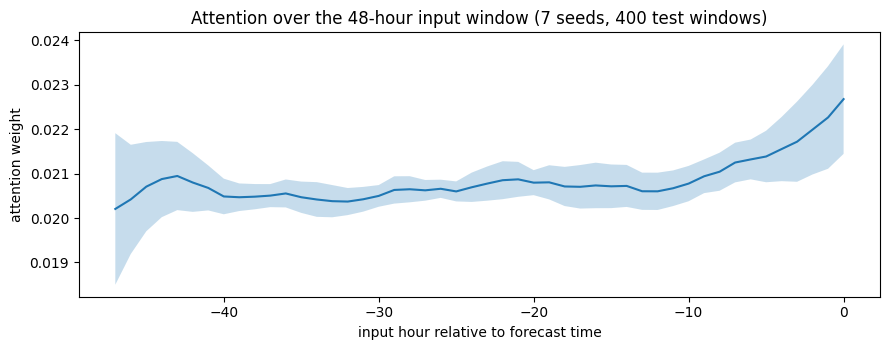

In [12]:
# VIEW 1 - attention: how much weight the last position puts on each of the 48 input hours
def attn_profile(model):
    store = []
    hk = model.attn.register_forward_hook(lambda mod, inp, out: store.append(out[1].detach().cpu()))   # (B*n, 48, 48), mean over heads
    with torch.no_grad():
        for i in range(0, len(Xs_), 50):
            sl = slice(i, i + 50)
            model(Xs_[sl].to(DEVICE), At_[sl].to(DEVICE), Afc_[sl].to(DEVICE), TF_[sl].to(DEVICE), Anc_[sl].to(DEVICE))
    hk.remove()
    w = torch.cat(store)[:, -1, :]                                   # last query -> weights over 48 input hours
    return w.mean(0).numpy()

prof = np.stack([attn_profile(m) for m in models])                   # (7, 48)
mean_prof, sd_prof = prof.mean(0), prof.std(0)
lags = np.arange(-47, 1)
blocks = {'last 6 h': slice(42, 48), 'hours 7-24 back': slice(24, 42), 'hours 25-48 back': slice(0, 24)}
attn_mass = {k: float(mean_prof[v].sum()) for k, v in blocks.items()}
print('attention mass by block:', {k: round(v, 3) for k, v in attn_mass.items()})

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(lags, mean_prof, color='tab:blue'); ax.fill_between(lags, mean_prof - sd_prof, mean_prof + sd_prof, alpha=0.25)
ax.set_xlabel('input hour relative to forecast time'); ax.set_ylabel('attention weight')
ax.set_title('Attention over the 48-hour input window (7 seeds, 400 test windows)')
plt.tight_layout(); plt.savefig(os.path.join(PLOT_DIR, 'xai_attention.png'), dpi=160); plt.show()

# HOW TO CHECK: weights sum to 1 across the 48 hours; most mass is usually on the most recent hours.
# Attention alone is not proof of importance - view 1b checks it with a permutation test.

In [13]:
# VIEW 1b - sanity check: blank out blocks of input hours (set to the training mean) and see the error rise
res_block = {}
for name, sl in blocks.items():
    Xm = Xs_.clone(); Xm[:, sl, :, :] = 0.0                          # 0 = training mean after StandardScaler
    res_block[name] = rmse_of(ens_pred(X=Xm)) - full_rmse
    print(f'blank {name:18}: RMSE +{res_block[name]:.2f}')

# HOW TO CHECK: if attention and this test agree (recent hours matter most) the attention picture is trustworthy.

blank last 6 h          : RMSE +10.94
blank hours 7-24 back   : RMSE +12.69
blank hours 25-48 back  : RMSE +10.84


coalitions evaluated: 64
RMSE with all groups 61.18 | with none 94.65
  PM2.5 history        35.2 % of the error reduction
  Weather (T, RH)      34.6 % of the error reduction
  City context         18.3 % of the error reduction
  Calendar (input)     13.3 % of the error reduction
  Wind                  7.0 % of the error reduction
  Other pollutants     -8.3 % of the error reduction


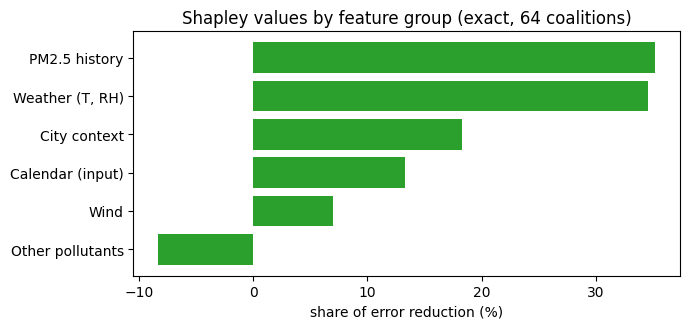

In [14]:
# VIEW 2 - exact Shapley values over six feature groups (2^6 = 64 coalitions, absent group = training mean)
groups = {
    'PM2.5 history':   ['pm2.5','pm_roll6_mean','pm_roll6_std','pm_roll24_mean','pm_roll24_std','pm_delta3'],
    'Other pollutants':['pm10','no2','so2','co','o3'],
    'Weather (T, RH)': ['rh','at'],
    'Wind':            ['u_wind','v_wind','wspd'],
    'City context':    ['city_mean_pm','city_max_pm','pm_minus_city'],
    'Calendar (input)':['hour_sin','hour_cos','dow_sin','dow_cos','mon_sin','mon_cos','is_weekend'],
}
gnames = list(groups)
gidx = {g: [FEATURE_COLS.index(c) for c in cols] for g, cols in groups.items()}
assert sum(len(v) for v in gidx.values()) == F

import itertools, math
n_g = len(gnames)
value = {}                                                            # frozenset of present groups -> MSE (ug/m3)^2
for r in range(n_g + 1):
    for S in itertools.combinations(range(n_g), r):
        Xm = Xs_.clone()
        for gi in range(n_g):
            if gi not in S:
                Xm[:, :, :, gidx[gnames[gi]]] = 0.0
        p = ens_pred(X=Xm)
        value[frozenset(S)] = float(np.mean((p - y_true) ** 2))
print('coalitions evaluated:', len(value))

phi = np.zeros(n_g)
for g in range(n_g):
    others = [x for x in range(n_g) if x != g]
    for r in range(len(others) + 1):
        for S in itertools.combinations(others, r):
            wgt = math.factorial(r) * math.factorial(n_g - r - 1) / math.factorial(n_g)
            phi[g] += wgt * (value[frozenset(S)] - value[frozenset(S) | {g}])    # error reduction from adding group g
total = value[frozenset()] - value[frozenset(range(n_g))]
share = phi / total * 100
print(f"RMSE with all groups {np.sqrt(value[frozenset(range(n_g))]):.2f} | with none {np.sqrt(value[frozenset()]):.2f}")
for g, s in sorted(zip(gnames, share), key=lambda t: -t[1]):
    print(f'  {g:18} {s:6.1f} % of the error reduction')

fig, ax = plt.subplots(figsize=(7, 3.4))
order = np.argsort(share)
ax.barh([gnames[i] for i in order], share[order], color='tab:green')
ax.set_xlabel('share of error reduction (%)'); ax.set_title('Shapley values by feature group (exact, 64 coalitions)')
plt.tight_layout(); plt.savefig(os.path.join(PLOT_DIR, 'xai_shapley.png'), dpi=160); plt.show()

# HOW TO CHECK: shares add up to about 100 %. Note the last observed PM2.5 is also fed to the model separately
# (the gated anchor), so even the 'none' coalition is not a blind model.

top 15 edges (information flows from the second station into the first):
  Burari Crossing              <- Alipur                         1.71 % of total sensitivity
  NSIT Dwarka                  <- Mundka                         1.42 % of total sensitivity
  Najafgarh                    <- NSIT Dwarka                    1.34 % of total sensitivity
  Jahangirpuri                 <- Alipur                         1.18 % of total sensitivity
  Mundka                       <- Bawana                         1.17 % of total sensitivity
  Alipur                       <- Narela                         1.08 % of total sensitivity
  ITO                          <- Chandni Chowk                  1.07 % of total sensitivity
  Vivek Vihar                  <- Anand Vihar                    0.93 % of total sensitivity
  Bawana                       <- Narela                         0.92 % of total sensitivity
  CRRI Mathura Road            <- Nehru Nagar                    0.90 % of total sensitivi

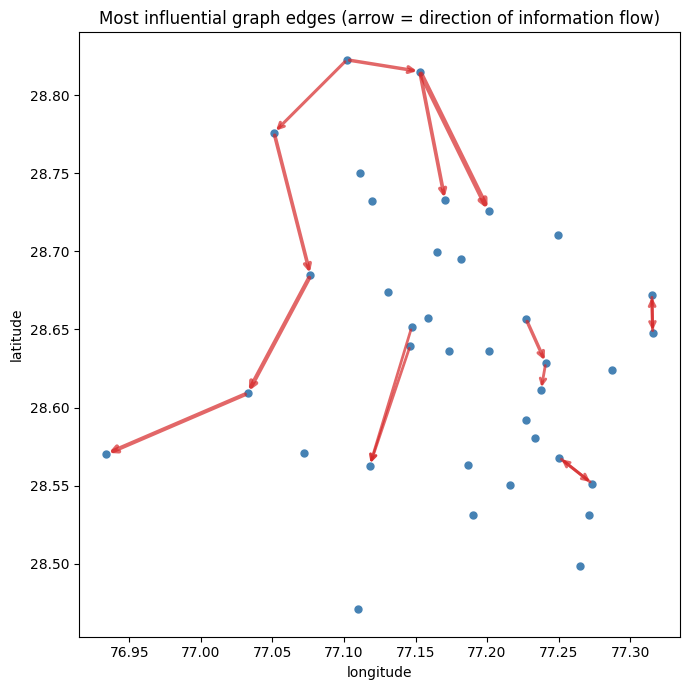

In [16]:
# VIEW 3 - edge sensitivity: |d forecast / d A[i,j]| x A[i,j], averaged over windows, lags and seeds
# Convention: the model computes h_i = sum_j A[i,j] h_j, so edge (i, j) carries information from j into i.
edge_score = np.zeros((N, N)); n_acc = 0
for m in models:
    for i in range(0, min(200, len(Xs_)), 25):                        # up to 200 windows keep memory small
        sl = slice(i, min(i + 25, len(Xs_)))
        At = At_[sl].clone().to(DEVICE).requires_grad_(True)
        with torch.backends.cudnn.flags(enabled=False):               # cuDNN's GRU cannot run backward in eval mode
            out = m(Xs_[sl].to(DEVICE), At, Afc_[sl].to(DEVICE), TF_[sl].to(DEVICE), Anc_[sl].to(DEVICE))
            out.mean().backward()
        edge_score += (At.grad * At).abs().mean(dim=(0, 1)).detach().cpu().numpy()
        n_acc += 1
edge_score /= n_acc
np.fill_diagonal(edge_score, 0)
flat = np.dstack(np.unravel_index(np.argsort(-edge_score.ravel()), edge_score.shape))[0][:15]
total_s = edge_score.sum()
print('top 15 edges (information flows from the second station into the first):')
for i, j in flat:
    print(f'  {station_names[i][:28]:28} <- {station_names[j][:28]:28}  {edge_score[i, j] / total_s * 100:5.2f} % of total sensitivity')
print(f'top 15 edges hold {sum(edge_score[i, j] for i, j in flat) / total_s * 100:.1f} % of all edge sensitivity')

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(lons, lats, s=25, color='steelblue', zorder=3)
mx = edge_score[tuple(flat.T)].max()
for i, j in flat:
    ax.annotate('', xy=(lons[i], lats[i]), xytext=(lons[j], lats[j]),
                arrowprops=dict(arrowstyle='->', lw=0.6 + 3 * edge_score[i, j] / mx, color='tab:red', alpha=0.7))
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.set_title('Most influential graph edges (arrow = direction of information flow)')
plt.tight_layout(); plt.savefig(os.path.join(PLOT_DIR, 'xai_edges.png'), dpi=160); plt.show()

In [17]:
# save the numbers
out = {
    'sample_windows': int(len(sel)), 'sample_rmse': full_rmse, 'test_rmse_full': ens['rmse'],
    'attention_mass_by_block': attn_mass, 'blank_block_rmse_increase': res_block,
    'shapley_share_percent': dict(zip(gnames, [float(x) for x in share])),
    'rmse_all_groups': float(np.sqrt(value[frozenset(range(n_g))])), 'rmse_no_groups': float(np.sqrt(value[frozenset()])),
    'top_edges': [{'receiver': station_names[i], 'sender': station_names[j], 'share_percent': float(edge_score[i, j] / total_s * 100)} for i, j in flat],
}
json.dump(out, open(os.path.join(RESULTS_DIR, 'xai_results.json'), 'w'), indent=2)
print('saved results/xai_results.json and plots/xai_attention.png, xai_shapley.png, xai_edges.png')

saved results/xai_results.json and plots/xai_attention.png, xai_shapley.png, xai_edges.png
